# BIOT 6900 · Module 2 — Multi-Omics Target Identification & Validation
### Week 2 · Computational Lab 2 · Starter Notebook

**What this notebook does.** You'll integrate three data layers — transcriptomics (RNA), proteomics (protein), and genomics — to nominate and *rank* disease targets, then hand that ranked list to Weeks 3–4.

**How today is built — I do → we do → you do:**
- **Part 1 (worked, already complete):** CPTAC **breast cancer** on *synthetic* data. The tumors are measured at all three layers, so the data is *sample-matched* — you integrate **at the sample level**. Your instructor runs these cells; follow along.
- **Part 2 (together, in class):** find and load *real* CPTAC data, then re-run Part 1 on real numbers. Not graded.
- **Part 3 (your assignment, `# TODO` cells):** **Alzheimer's disease**. The cohorts are *not* matched across layers, so you integrate **at the gene level**. You transfer the Part 1 method to messier, more realistic data.

> **The one idea to carry through:** *how* you integrate is dictated by *what your data has matched.* Matched → correlate within samples. Unmatched → compare gene-level summaries. Same goal, different machinery.

**Data.** Part 1 looks for the synthetic CPTAC files in `data/` and, if they're absent, falls back to clearly-labelled demo data so it always runs. Part 3 requires the three Alzheimer's matrices posted on **Canvas** — place them in `data/` (see the Lab Guide).

*Continuity from Module 1:* you'll see **TP53 / p53** (`P04637`, PDB `1TUP`) surface in the cancer half and **APOE** (`rs7412`) in the Alzheimer's half.

**Before you submit:** `Kernel → Restart & Run All` so the whole notebook executes top to bottom.

In [16]:
import os
import numpy as np
import pandas as pd
from scipy import stats

RNG = np.random.default_rng(6900)  # fixed seed so results are reproducible

# Module 1 continuity anchors
P53_UNIPROT, P53_PDB = "P04637", "1TUP"   # p53  -> cancer half
APOE_VARIANT = "rs7412"                    # APOE -> Alzheimer's half

# Default scoring weights for this course: equal across the three layers.
# You MAY change these in Part 3 — but if you do, you must justify it in your report.
EQUAL_WEIGHTS = {"transcriptomic": 1/3, "proteomic": 1/3, "genomic": 1/3}

## Helper functions you'll use in both parts
Two small functions do the scoring work. `rank_percentile` puts any layer's scores on a common 0–1 scale (by rank, so it's robust to outliers and to layers being on different units). `multi_evidence_score` normalizes each layer and takes the weighted sum.

In [17]:
def rank_percentile(series: pd.Series) -> pd.Series:
    """Normalize any score to [0, 1] by rank. Robust to outliers and scale differences."""
    return series.rank(method="average", pct=True)


def multi_evidence_score(df: pd.DataFrame, cols, weights) -> pd.Series:
    """Weighted sum of rank-percentile-normalized layer scores."""
    normed = pd.DataFrame({c: rank_percentile(df[c]) for c in cols})
    return sum(weights[c] * normed[c] for c in cols)

## Data loading (provided — you don't need to edit these)
`load_cptac()` reads the matched breast-cancer matrices for Part 1 (or synthesizes demo data if they're missing). `load_ad()` reads the three Alzheimer's matrices you download from Canvas for Part 2.

In [18]:
CPTAC_GENES = ["TP53", "PIK3CA", "ERBB2", "ESR1", "GATA3", "MYC", "CDH1",
               "MAP3K1", "PTEN", "AKT1", "RB1", "CCND1", "FOXA1", "MKI67",
               "EGFR", "BRCA1", "BRCA2", "KRT5", "VIM", "ACTB"]


def _synth_cptac(n_tumor=60, n_normal=15):
    genes = CPTAC_GENES
    tumor_ids = [f"T{i:02d}" for i in range(n_tumor)]
    normal_ids = [f"N{i:02d}" for i in range(n_normal)]
    coupling = pd.Series(RNG.uniform(0.05, 0.80, len(genes)), index=genes)

    def gene_matrix(sample_ids, shift):
        rna = pd.DataFrame(RNG.normal(0, 1, (len(genes), len(sample_ids))),
                           index=genes, columns=sample_ids).add(shift, axis=0)
        noise = pd.DataFrame(RNG.normal(0, 1, rna.shape), index=genes, columns=sample_ids)
        prot = rna.mul(coupling, axis=0) + noise.mul(1 - coupling + 0.35, axis=0)
        return rna, prot

    shift = pd.Series(0.0, index=genes)
    for g in ["TP53", "ERBB2", "MKI67", "MYC", "PIK3CA"]:
        shift[g] = RNG.uniform(1.2, 2.2)
    rna_t, prot_t = gene_matrix(tumor_ids, shift)
    rna_n, prot_n = gene_matrix(normal_ids, pd.Series(0.0, index=genes))
    rna = pd.concat([rna_t, rna_n], axis=1)
    prot = pd.concat([prot_t, prot_n], axis=1)
    mut_freq = pd.Series(RNG.uniform(0.0, 0.05, len(genes)), index=genes)
    for g in ["TP53", "PIK3CA", "CDH1", "GATA3"]:
        mut_freq[g] = RNG.uniform(0.25, 0.45)
    meta = pd.Series(["tumor"] * n_tumor + ["normal"] * n_normal,
                     index=tumor_ids + normal_ids, name="group")
    return rna, prot, mut_freq, meta


def load_cptac():
    p = {"rna": "data/cptac_brca_rna.tsv", "prot": "data/cptac_brca_protein.tsv",
         "mut": "data/cptac_brca_mutation.tsv"}
    if all(os.path.exists(v) for v in p.values()):
        rna = pd.read_csv(p["rna"], sep="\t", index_col=0)
        prot = pd.read_csv(p["prot"], sep="\t", index_col=0)
        mut = pd.read_csv(p["mut"], sep="\t", index_col=0).iloc[:, 0]
        print("Loaded CPTAC files from data/.")
        return rna, prot, mut, None
    print("!! WARNING: CPTAC files not found -> SYNTHETIC demo data "
          "(illustrative only, not real CPTAC values).")
    return _synth_cptac()


def load_ad():
    p = {"tx": "data/ad_transcriptomics.tsv", "pr": "data/ad_proteomics.tsv",
         "gw": "data/ad_gwas.tsv"}
    missing = [v for v in p.values() if not os.path.exists(v)]
    if missing:
        raise FileNotFoundError(
            "Alzheimer's matrices not found: " + ", ".join(missing) +
            "\nDownload the three files from Canvas and put them in a 'data/' folder "
            "next to this notebook (see the Lab Guide).")
    return (pd.read_csv(p["tx"], sep="\t"),
            pd.read_csv(p["pr"], sep="\t"),
            pd.read_csv(p["gw"], sep="\t"))

---
# Part 1 — Worked example: CPTAC breast cancer *(run and read; nothing to edit)*

**Why integrate at all?** Each layer can produce artifacts the others don't share, so a target supported across genome, transcriptome, and proteome is a stronger bet than one seen in only one layer. Integration is triangulation.

Because CPTAC measures the **same tumors** at every layer, we can line samples up and integrate **at the sample level.**

In [19]:
rna, prot, mut_freq, meta = load_cptac()
print("RNA matrix:    ", rna.shape, "(genes x samples)")
print("Protein matrix:", prot.shape)
print("Mutation freq: ", mut_freq.shape)

Loaded CPTAC files from data/.
RNA matrix:     (23121, 122) (genes x samples)
Protein matrix: (12621, 122)
Mutation freq:  (9448,)


### 1.2 Harmonize identifiers → a common gene key
The real technical wall in multi-omics: gene symbols, Ensembl IDs, and UniProt accessions don't line up for free. Here we intersect on a shared key and check how many genes *survive the join* — always your first reality check.

In [20]:
common = rna.index.intersection(prot.index).intersection(mut_freq.index)
print(f"Genes surviving the 3-way join: {len(common)} "
      f"(RNA {len(rna.index)}, protein {len(prot.index)}, mutation {len(mut_freq.index)})")
rna, prot, mut_freq = rna.loc[common], prot.loc[common], mut_freq.loc[common]
samples = rna.columns.intersection(prot.columns)

Genes surviving the 3-way join: 6306 (RNA 23121, protein 12621, mutation 9448)


### 1.3–1.4 Sample-level RNA–protein correlation
With matched samples we can ask, per gene, *does protein track RNA across patients?* The answer is usually **partial** — correlation is modest and varies by gene. A gene where protein does **not** track RNA isn't broken data; it's a signal of post-transcriptional regulation (translational buffering, protein turnover).

In [21]:
corr = pd.Series(
    {g: stats.spearmanr(rna.loc[g, samples], prot.loc[g, samples]).statistic
     for g in common}, name="rna_prot_corr")
print(f"RNA-protein correlation: median={corr.median():.2f}, "
      f"range=[{corr.min():.2f}, {corr.max():.2f}]   <- note: NOT ~1.0")
print(f"  most coupled: {corr.idxmax()} ({corr.max():.2f});  "
      f"most buffered: {corr.idxmin()} ({corr.min():.2f})")

RNA-protein correlation: median=0.48, range=[-0.23, 0.92]   <- note: NOT ~1.0
  most coupled: VWA5A (0.92);  most buffered: ARPC1A (-0.23)


**Read this result.** The median correlation is well below 1 — most genes' protein levels only partly follow their RNA. That is the empirical reason you can't treat RNA as a stand-in for protein, and why integrating both layers adds information.

### 1.5 Per-layer differential signal
Each layer independently nominates candidates. Here the signal is the tumor-vs-normal effect size at RNA and protein, plus per-gene mutation frequency for the genomic layer.

In [22]:
if meta is not None:
    tcols = meta.index[meta == "tumor"]
    ncols = meta.index[meta == "normal"]
    rna_eff = (rna[tcols].mean(axis=1) - rna[ncols].mean(axis=1)).abs()
    prot_eff = (prot[tcols].mean(axis=1) - prot[ncols].mean(axis=1)).abs()
else:
    rna_eff = rna[samples].mean(axis=1).abs()
    prot_eff = prot[samples].mean(axis=1).abs()

scored = pd.DataFrame({"transcriptomic": rna_eff, "proteomic": prot_eff,
                       "genomic": mut_freq, "rna_prot_corr": corr})
scored.round(3).head()

,transcriptomic,proteomic,genomic,rna_prot_corr
A2M,0.060,0.494,0.033,0.349
A2ML1,0.954,3.147,0.016,NaN
AADACL2,0.499,0.396,0.008,NaN
AAED1,0.070,0.434,0.016,NaN
AAGAB,0.026,0.211,0.008,0.666


### 1.6 Multi-evidence score → ranked targets
Normalize each layer to a common scale and take the **equal-weighted** sum. This turns three noisy layers into one ranked list — the artifact everything downstream consumes.

In [23]:
scored["score"] = multi_evidence_score(
    scored, ["transcriptomic", "proteomic", "genomic"], EQUAL_WEIGHTS)
ranked_cptac = scored.sort_values("score", ascending=False)
print("Top CPTAC targets (worked example):")
print(ranked_cptac.head(6).round(3).to_string())
# Continuity check: TP53 / p53 (Module 1's P04637 / 1TUP) is a top breast-cancer hit.
print("\nTP53 rank:", list(ranked_cptac.index).index("TP53") + 1)

Top CPTAC targets (worked example):
         transcriptomic  proteomic  genomic  rna_prot_corr  score
SI                0.977      5.200    0.049            NaN  0.988
VWDE              1.263      1.424    0.049            NaN  0.979
MUC5B             0.566      3.441    0.082            NaN  0.978
SPHKAP            0.573      3.321    0.041            NaN  0.970
CEACAM5           0.813      3.315    0.033            NaN  0.970
RIMS2             1.240      1.676    0.033            NaN  0.968

TP53 rank: 108


### Part 1 recap
You integrated **at the sample level** because the data was **matched** — you could correlate RNA and protein within the same tumors. That was synthetic data, so the method is easy to see. Next we run it on real data, then you transfer it to unmatched data yourself.

---
# Part 2 — Find and load real CPTAC data *(together, in class)*

Now swap the synthetic files for the real thing. CPTAC breast data is open access (no data-use agreement) — we'll get it together in class. **Not graded.**

1. Go to **LinkedOmics** (`linkedomics.org`) → **CPTAC Breast Cancer (BRCA)**.
2. Download the gene-level **RNAseq** and **Proteome** matrices (gene × sample).
3. Save them into `data/` with genes as the row index and these exact names — transpose with `.T` first if samples are in rows:
   - `data/cptac_brca_rna.tsv`
   - `data/cptac_brca_protein.tsv`
   - `data/cptac_brca_mutation.tsv`  (one row per gene: mutation frequency or CNV magnitude)
4. `Kernel → Restart & Run All` and watch **Part 1** again — it now loads your real files instead of the demo. Compare: is the RNA–protein correlation still modest? Does TP53 still surface near the top?

*Wrinkle:* the real download has no tumor/normal labels, so ranking falls back to overall abundance rather than a tumor-vs-normal effect. That's fine for seeing the pipeline run on real data.

---
# Part 3 — Your assignment

I chose to work on colon cancer with data from Linkomics.

### 3.1 — TODO: load and inspect the three matrices

In [24]:
# I used data from Linkedomics, so I repurposed the data cleaning tool from Part 2. 

import os
import pandas as pd

OUT_DIR = "data" 
RAW_DIR = "." 

FILES = {
    "rna":  "data/Human__CPTAC_COAD__UNC__RNAseq__HiSeq_RNA__03_01_2017__BCM__Gene__BCM_RSEM_UpperQuartile_log2.cct.gz", # tumors only
    "tcga_rna": "data/TCGA.COAD.sampleMap_HiSeqV2.gz", # This contains both tumors and non-tumors 
    "prot": "data/Human__CPTAC_COAD__PNNL__Proteome__TMT__03_01_2017__BCM__Gene__Tumor_Normal_log2FC.cct",
    "mut":  "data/Human__CPTAC_COAD__WUSM__Mutation__GAIIx__03_01_2017__BCM__Gene__GATK_Pipeline.cbt",
}

os.makedirs(OUT_DIR, exist_ok=True)

def read_matrix(name):
    """Read a LinkedOmics .cct/.cbt matrix from disk and
    orient it so GENES are the rows. No manual steps needed."""
    src = os.path.join(RAW_DIR, name)
    df = pd.read_csv(src, sep="\t", index_col=0)
    # genes are the long axis (thousands) vs ~122 samples; make genes the rows
    if df.shape[0] < df.shape[1]:
        df = df.T
    return df

rna = read_matrix(FILES["rna"])
rna.to_csv(os.path.join(OUT_DIR, "cptac_colon_rna.tsv"), sep="\t")
print("RNA     ->", rna.shape, "(genes x samples)")

# Data handling for the tcga data. 01 are tumors, 11 are normal.
tcga_rna = read_matrix(FILES["tcga_rna"])
codes = tcga_rna.columns.str.split("-").str[3].str[:2]
meta = pd.Series(codes, index=tcga_rna.columns).map({"01": "tumor", "11": "normal"}).dropna()
print("TCGA RNA ->", tcga_rna.shape, "(genes x samples)")

prot = read_matrix(FILES["prot"])
prot.to_csv(os.path.join(OUT_DIR, "cptac_colon_protein.tsv"), sep="\t")
print("Protein ->", prot.shape, "(genes x samples)")

# --- Mutation: binary matrix -> one number per gene (fraction of tumors mutated) ---
mut = read_matrix(FILES["mut"]).apply(pd.to_numeric, errors="coerce")
mut_freq = mut.mean(axis=1)
mut_freq.name = "mut_freq"
mut_freq.to_frame().to_csv(os.path.join(OUT_DIR, "cptac_colon_mutation.tsv"), sep="\t")
print("Mutation->", mut_freq.shape[0], "genes (collapsed to per-gene frequency)")

shared = rna.columns.intersection(prot.columns)
print(f"\nRNA/protein shared tumor samples: {len(shared)} ")

RNA     -> (13482, 106) (genes x samples)
TCGA RNA -> (20530, 329) (genes x samples)
Protein -> (6422, 96) (genes x samples)
Mutation-> 15174 genes (collapsed to per-gene frequency)

RNA/protein shared tumor samples: 95 


### 3.2 — TODO: harmonize on the gene symbol → one joined table

In [25]:
common = rna.index.intersection(prot.index).intersection(mut_freq.index).intersection(tcga_rna.index)
print(f"Genes surviving the 4-way join: {len(common)} "
      f"(RNA {len(rna.index)}, protein {len(prot.index)}, mutation {len(mut_freq.index)})")
rna, prot, mut_freq, tcga_rna = rna.loc[common], prot.loc[common], mut_freq.loc[common], tcga_rna.loc[common]
samples = rna.columns.intersection(prot.columns)

Genes surviving the 4-way join: 4470 (RNA 13482, protein 6422, mutation 15174)


### 3.3 — TODO: concordance

In [26]:
corr = pd.Series(
    {g: stats.spearmanr(rna.loc[g, samples], prot.loc[g, samples]).statistic
     for g in common}, name="rna_prot_corr")
print(f"RNA-protein correlation: median={corr.median():.2f}, "
      f"range=[{corr.min():.2f}, {corr.max():.2f}]")
print(f"  most coupled: {corr.idxmax()} ({corr.max():.2f});  "
      f"most buffered: {corr.idxmin()} ({corr.min():.2f})")

RNA-protein correlation: median=0.30, range=[-0.32, 0.83]
  most coupled: ABAT (0.83);  most buffered: C4BPA (-0.32)


### 3.4 — TODO: multi-evidence score

In [ ]:
if meta is not None:
    tcols = meta.index[meta == "tumor"]
    ncols = meta.index[meta == "normal"]
    # Use the tcga data for tumor vs normal data instead
    rna_eff = (tcga_rna[tcols].mean(axis=1) - tcga_rna[ncols].mean(axis=1)).abs()
    prot_eff = prot[samples].mean(axis=1).abs()
else:
    rna_eff = rna[samples].mean(axis=1).abs()
    prot_eff = prot[samples].mean(axis=1).abs()

scored = pd.DataFrame({"transcriptomic": rna_eff, "proteomic": prot_eff,
                       "genomic": mut_freq, "rna_prot_corr": corr})
scored.round(3).head()

,transcriptomic,proteomic,genomic,rna_prot_corr
A1CF,1.563,0.197,0.009,NaN
A2M,1.491,1.317,0.075,-0.026
AACS,0.007,0.239,0.038,0.320
AAK1,0.600,0.209,0.047,0.017
AAMP,0.015,0.097,0.019,0.260


### 3.5 — TODO: rank, inspect, and export
Sort by score, take the top ~15, and **export the ranked table to `targets_ad.csv`** — this file is the hand-off to Week 3. 

In [31]:
scored["score"] = multi_evidence_score(
    scored, ["transcriptomic", "proteomic", "genomic"], EQUAL_WEIGHTS)
ranked_cptac = scored.sort_values("score", ascending=False)
print("Top CPTAC targets (worked example):")
print(ranked_cptac.head(15).round(3).to_string())
ranked_cptac.head(15).round(3).to_csv("targets_ad.csv", index=True)

Top CPTAC targets (worked example):
          transcriptomic  proteomic  genomic  rna_prot_corr  score
FCGBP              4.449      1.820    0.151          0.543  0.992
MYH11              4.422      2.762    0.113          0.427  0.992
ANK2               3.499      1.521    0.142          0.393  0.986
FLNC               2.444      2.170    0.132          0.164  0.984
CP                 3.924      1.175    0.113         -0.025  0.977
KCNMA1             3.546      1.028    0.160            NaN  0.976
MYLK               2.896      2.262    0.085          0.459  0.975
DMD                1.912      1.569    0.179          0.404  0.975
COL1A1             2.276      1.887    0.085          0.277  0.968
COLEC12            2.573      1.867    0.075            NaN  0.965
EPB41L3            3.520      1.376    0.075          0.628  0.964
MUC2               3.131      1.023    0.094          0.587  0.963
SORBS2             1.489      1.935    0.113          0.143  0.962
PPP1R12B           2.109  

### 3.6 — Venn Diagram

Compare the genes in the top 10% of each layer's rank-percentile scores. This uses a relative cutoff because RNA, protein, and mutation measurements have different scales. Genes in overlaps have strong evidence in multiple layers.

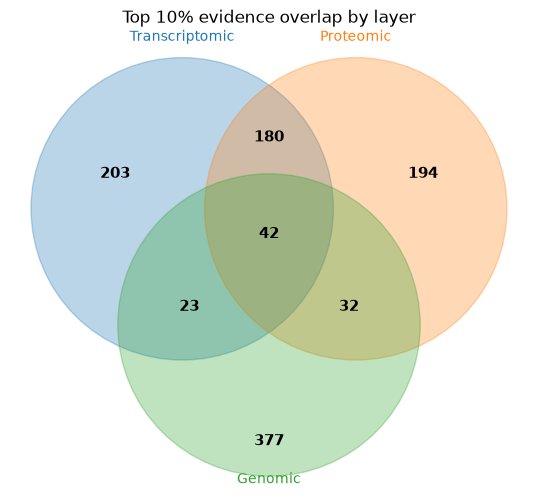

Genes in each layer's top-decile set:
transcriptomic   448
proteomic        448
genomic          474

Exclusive Venn regions:
Transcriptomic only            203
Proteomic only                 194
Genomic only                   377
Transcriptomic + proteomic     180
Transcriptomic + genomic       23
Proteomic + genomic            32
All three layers               42


In [29]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

LAYERS = ["transcriptomic", "proteomic", "genomic"]
TOP_FRACTION = 0.10
layer_sets = {
    layer: set(scored.index[rank_percentile(scored[layer]) >= 1 - TOP_FRACTION])
    for layer in LAYERS
}
tx, protein, genomic = (layer_sets[layer] for layer in LAYERS)
regions = {
    "Transcriptomic only": tx - protein - genomic,
    "Proteomic only": protein - tx - genomic,
    "Genomic only": genomic - tx - protein,
    "Transcriptomic + proteomic": (tx & protein) - genomic,
    "Transcriptomic + genomic": (tx & genomic) - protein,
    "Proteomic + genomic": (protein & genomic) - tx,
    "All three layers": tx & protein & genomic,
}

fig, ax = plt.subplots(figsize=(8, 6))
circles = [
    Circle((-0.62, 0.28), 1.08, color="tab:blue", alpha=0.30),
    Circle((0.62, 0.28), 1.08, color="tab:orange", alpha=0.30),
    Circle((0.00, -0.55), 1.08, color="tab:green", alpha=0.30),
]
for circle in circles:
    ax.add_patch(circle)

label_positions = {
    "Transcriptomic only": (-1.10, 0.53),
    "Proteomic only": (1.10, 0.53),
    "Genomic only": (0.00, -1.38),
    "Transcriptomic + proteomic": (0.00, 0.79),
    "Transcriptomic + genomic": (-0.57, -0.42),
    "Proteomic + genomic": (0.57, -0.42),
    "All three layers": (0.00, 0.10),
}
for region, position in label_positions.items():
    ax.text(*position, str(len(regions[region])), ha="center", va="center",
            fontsize=11, fontweight="bold")

ax.set_xlim(-1.85, 1.85)
ax.set_ylim(-1.75, 1.55)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"Top {TOP_FRACTION:.0%} evidence overlap by layer")
ax.text(-0.62, 1.48, "Transcriptomic", ha="center", color="tab:blue")
ax.text(0.62, 1.48, "Proteomic", ha="center", color="tab:orange")
ax.text(0.00, -1.68, "Genomic", ha="center", color="tab:green")
plt.show()

print("Genes in each layer's top-decile set:")
for layer, genes in layer_sets.items():
    print(f"{layer:16s} {len(genes)}")
print("\nExclusive Venn regions:")
for region, genes in regions.items():
    print(f"{region:30s} {len(genes)}")

---
### Submit (Part 3 only)
1. `Kernel → Restart & Run All` — confirm the whole notebook runs top to bottom.
2. Commit **this notebook**, **`targets_ad.csv`**, and a short **README** (your name + anything that didn't work) to your `biot6900` repo.
3. Push, confirm the files appear on github.com, then **post your repo link on Canvas.**

Grading follows the course 60 / 40 split — 60 execution, 40 interpretation & communication. Partial credit for a correct approach even with minor technical errors: if a step wouldn't run, say what you were trying to do and what happened.